# **Feature Engineering**

**Objetivo:** Analizar cómo las características comerciales de los productos del ecosistema móvil de Falabella Perú (marca, vendedor, descuentos y volumen de reseñas) determinan su precio final.

**Propósito del notebook:**
Tomar el dataset limpio (`dataset_inicial.csv`) que conserva la dispersión real del mercado (desde accesorios económicos hasta smartphones de gama ultra-alta de S/ 12,000) y aplicar técnicas de Feature Engineering:
1. **Generación de características:** Operaciones matemáticas, indicadores de nulos, *binning* y frecuencias.
2. **Transformación de características:** Mitigación de asimetría (*skewness*) con raíz cuadrada y logaritmo, además de codificación categórica (*Label Encoding* y *One-Hot Encoding*).
3. **Escalado de características:** Normalización (`MinMaxScaler`) y Estandarización (`StandardScaler`).

# Carga de librerías y de los datos

In [5]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Cargamos el dataset limpio de la etapa anterior
df = pd.read_csv("dataset_inicial.csv")

print(f"Dimensiones del dataset: {df.shape}")

Dimensiones del dataset: (1830, 9)


# Creación de variables

### **1. Generación de Características Matemáticas e Indicadores**

* **Ahorro en soles (`ahorro`):** Aunque ya contamos con el porcentaje de `descuento`, un 20% de descuento en una funda de S/ 30 no representa el mismo impacto económico que un 20% en un iPhone de S/ 6,000. Restamos el `precio_original` menos el `precio` para obtener el ahorro monetario real.
* **Indicador de producto con reseñas (`tiene_resenas`):** En la limpieza vimos que `calificacion_con_resenas` tiene 933 valores nulos (`NaN`) que corresponden a productos nuevos o "fantasmas" sin opiniones. En lugar de perder ese patrón, creamos una columna binaria (`1` si tiene reseñas, `0` si está vacío) para evaluar si el simple hecho de tener opiniones influye en el precio.

In [6]:
df["ahorro"] = df["precio_original"] - df["precio"]

# Creación de variable binaria sobre los nulos de calificacion_con_resenas
# Si es No Nulo le asignamos 1, de lo contrario 0
df["tiene_resenas"] = df["calificacion_con_resenas"].notnull() * 1

display(df.head(2))

,marca,nombre,vendedor,precio,precio_original,descuento,calificacion,cantidad_resenas,calificacion_con_resenas,ahorro,tiene_resenas
0,APPLE,IPhone 14 128GB Morado Reacondicionado A2649,Por Electronic Deals Pe,1469.0,1999.0,26.51,4.2500,4,4.2500,530.0,1
1,XIAOMI,Batería externa Power Bank 20000mAh Integrated...,Por Xiaomi Tienda Oficial,79.0,89.0,11.24,4.7273,22,4.7273,10.0,1


### **2. Generación de Características por Agrupación (Binning)**

* **Gama del producto (`gama_precio`):** Debido a que decidimos mantener los *outliers* reales (productos hasta S/ 12,000) porque reflejan la naturaleza del catálogo completo (accesorios y celulares), necesitamos segmentar esta dispersión. Usamos `pd.cut()` para agrupar el `precio` en 4 categorías comerciales claras: `accesorio_bajo` (hasta S/ 250), `gama_media` (S/ 250 a S/ 1,500), `gama_alta` (S/ 1,500 a S/ 4,000) y `premium` (más de S/ 4,000).
* **Nivel de descuento (`nivel_descuento`):** Agrupamos el porcentaje de descuento en rangos (`sin_descuento`, `bajo`, `medio`, `alto`) para analizar las estrategias promocionales por bloques.

In [7]:
# Explorar los productos económicos para detectar dónde empiezan los smartphones reales
df_baratos = df[(df['precio'] > 0) & (df['precio'] < 600)].sort_values(by='precio')
display(df_baratos[['nombre', 'precio']].head(30))

,nombre,precio
1270,Guante Funda Manga Dedales Grip De Dedos Gamer...,7.00
352,CASE MAGSAFE TRANSPARENTE PARA IPHONE 17 PRO MAX,7.00
793,Señal de Extintor 20x30 cm.,7.90
721,Señal de Botiquín 15x22.5 cm.,7.90
1164,Señal de Prohibido el Ingreso 15x22.5 cm.,7.90
1516,Señal de Extintor Multipropósito 15x22.5 cm.,7.90
418,Funda Acuática Sumergible Protector de Agua pa...,7.99
1440,Dedales Fundas Antisudor Dedos Gamer,7.99
1462,Dedales Gamer Antisudor,8.00
1560,Convertidor Otg Lightning Adaptador a Tipo C,8.00


El accesorio con el precio más bajo es de 7 soles.

In [8]:
df_baratos_2 = df[(df['precio'] >= 280) & (df['precio'] <= 450)].sort_values(by='precio')
display(df_baratos_2[['nombre', 'precio']].head(30))

,nombre,precio
334,GIMBAL Estabilizador Soporte de Telefono Live ...,283.90
838,TELÉFONO FIJO INALÁMBRICO NEGRO KX-TG3452LCB,289.00
773,Adaptador de corriente dinámico de 40 W (máx. ...,299.00
347,Wave Beam 2 Audifono Inalámbrico con Cancelaci...,299.00
608,POWER BANK NEXODE 25000 MAH 200W PORTÁTIL PD Q...,299.90
1404,Smartphone Blade A35e 6.52 64 Gb Gris,319.00
346,AUDIFONO TUNE 770 NC BLUETOOTH NEGRO,321.90
228,Micrófono Inalámbrico UHF Dual BT-Q2M,327.90
607,Panel Solar Portatil Plegable 28w Cargador Usb...,329.90
722,Battery Pack 20000mah 45w Beige + Adaptador 45...,334.00


Como se puede observar, el primer celular registrado 'Smartphone Blade A35e 6.52 64 Gb Gris' tiene un valor de 319 soles, lo cual indica que es el celular con el precio más bajo dentro de nuestro dataset. Ahora, segmentar de 318.99 soles a más como celulares estaría mal, pues vemos que un audífono tiene el precio de 321 soles y no es un celular, sino un accesorio. De esta forma, para tratar con la superposición de precios, se realizará una calificación en base a los siguientes bins: economico, intermedio, gama_alta, premium.

In [9]:
# Clasificacion por segmento comercial
bins_precio = [0, 450, 1500, 4000, 15000]
etiquetas_precio = ["economico", "intermedio", "gama_alta", "premium"]
df["segmento_precio"] = pd.cut(df["precio"], bins=bins_precio, labels=etiquetas_precio)

# Discretización para el porcentaje de descuento
bins_desc = [-1, 0, 15, 35, 100]
etiquetas_desc = ["sin_descuento", "desc_bajo", "desc_medio", "desc_alto"]
df["nivel_desc"] = pd.cut(df["descuento"], bins=bins_desc, labels=etiquetas_desc)

# Comprobamos la distribución del catálogo
print("Distribución de los productos por segmento de precio:")
print(df["segmento_precio"].value_counts())

Distribución de los productos por segmento de precio:
segmento_precio
economico     1616
intermedio      91
gama_alta       87
premium         36
Name: count, dtype: int64


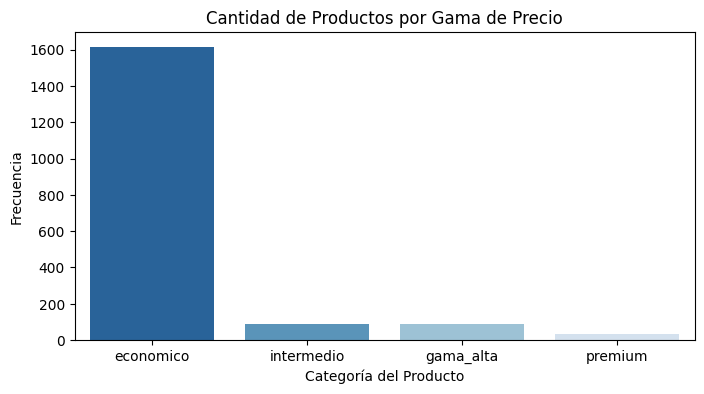

In [10]:
# Distribución de las gamas de producto
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="segmento_precio", palette="Blues_r")
plt.title("Cantidad de Productos por Gama de Precio")
plt.xlabel("Categoría del Producto")
plt.ylabel("Frecuencia")
plt.show()

## **3. Transformación de Características**

### 3.1 Transformaciones Logarítmicas (Reducción de Asimetría)
Las variables económicas (como `precio`) y de popularidad (como `cantidad_resenas`) suelen estar muy sesgadas hacia la derecha en el comercio electrónico. Aplicaremos `np.log()` para comprimir la escala y acercar su distribución a una campana normal. Sumamos `+1` a las reseñas para evitar el error matemático de calcular el logaritmo de 0.

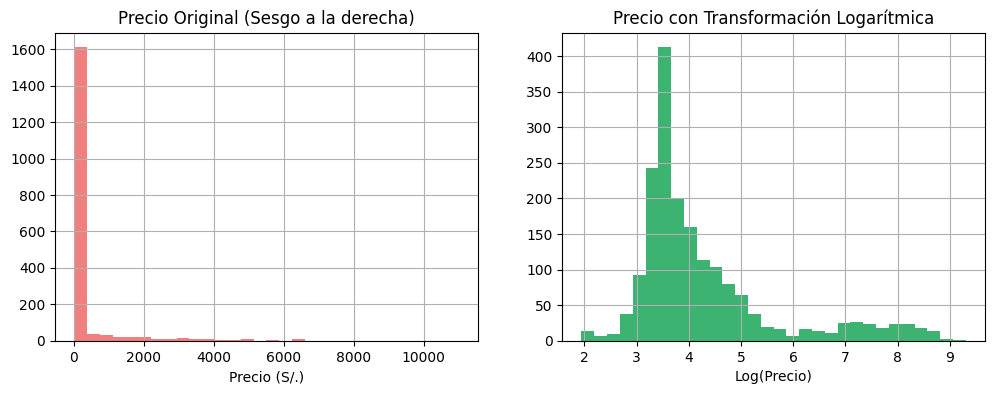

In [11]:
# Transformación logarítmica para suavizar el sesgo
df["precio_log"] = np.log(df["precio"])
df["resenas_log"] = np.log(df["cantidad_resenas"] + 1)

# Visualización del efecto de la transformación en el Precio
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df["precio"].hist(bins=30, color="lightcoral")
plt.title("Precio Original (Sesgo a la derecha)")
plt.xlabel("Precio (S/.)")

plt.subplot(1, 2, 2)
df["precio_log"].hist(bins=30, color="mediumseagreen")
plt.title("Precio con Transformación Logarítmica")
plt.xlabel("Log(Precio)")
plt.show()

La transformación aplicada no busca forzar una simetría perfecta, sino comprimir la escala de precios para estabilizar los modelos matemáticos. Esta gráfica resultante refleja la verdadera estructura del catálogo: el enorme pico izquierdo concentra el volumen masivo de accesorios económicos, mientras que la extensión derecha agrupa a los smartphones. Forzar una campana de Gauss perfecta implicaría distorsionar y perder la naturaleza comercial de nuestros datos.

### 3.2 Codificación de Variables Categóricas (Encoding)
Para que los algoritmos procesen los textos (`marca`, `vendedor`, `segmento_precio`), debemos convertirlos a números:
1. **Frecuencias (`vendedor_count`, `marca_freq`):** Calculamos cuántas veces aparece un vendedor o marca para medir su peso en el catálogo.
2. **Agrupación de marcas pequeñas (`marca_limpia`):** Marcas con menos de 10 productos se agrupan en `"otra_marca"` para evitar exceso de columnas ruidosas.
3. **Mapeo Ordinal:** Asignamos valores (0 a 3) a `segmento_precio` respetando su jerarquía de valor.
4. **One-Hot Encoding (`pd.get_dummies`):** Convertimos `marca_limpia` y `nivel_desc` en variables binarias (0 y 1).

In [12]:
# Frecuencias comerciales
df["vendedor_count"] = df["vendedor"].map(df["vendedor"].value_counts())
df["marca_count"] = df["marca"].map(df["marca"].value_counts())
df["marca_freq"] = round(df["marca"].map(df["marca"].value_counts(normalize=True)), 4)

# Agrupación y estilización de marcas
marcas_frecuentes = df["marca"].value_counts()[df["marca"].value_counts() >= 10].index
df["marca_limpia"] = df["marca"].apply(lambda x: x if x in marcas_frecuentes else "otra_marca")
df["marca_limpia"] = df["marca_limpia"].str.capitalize() # Deja los nombres como 'Apple', 'Xiaomi'

# Estilización de los niveles de descuento
mapeo_desc_corto = {
    "sin_descuento": "sin_desc",
    "desc_bajo": "bajo",
    "desc_medio": "medio",
    "desc_alto": "alto"
}
df["nivel_desc_corto"] = df["nivel_desc"].map(mapeo_desc_corto)

# Jerarquía de precios
mapeo_precio = {"economico": 0, "intermedio": 1, "gama_alta": 2, "premium": 3}
df["segmento_precio_num"] = df["segmento_precio"].map(mapeo_precio).astype(int)

# Generación de Dummies con nombres limpios
df_dummies = pd.get_dummies(df[["marca_limpia", "nivel_desc_corto"]], prefix=["marca", "nivel_desc"], dtype=int)


df_final = pd.concat([df, df_dummies], axis=1)

print("Nuevas columnas generadas:")
print(df_dummies.columns.tolist())

Nuevas columnas generadas:
['marca_Apple', 'marca_Belkin', 'marca_Case', 'marca_Generico', 'marca_Hoco', 'marca_Honor', 'marca_Ldnio', 'marca_Memo', 'marca_Motorola', 'marca_Nillkin', 'marca_Oem', 'marca_Otra_marca', 'marca_Ringke', 'marca_Samsung', 'marca_Seisa', 'marca_Shield', 'marca_Space', 'marca_Ugreen', 'marca_Xiaomi', 'nivel_desc_sin_desc', 'nivel_desc_bajo', 'nivel_desc_medio', 'nivel_desc_alto']


- Contamos cuántas veces aparece un vendedor y una marca en el dataset.
- Filtramos el número de frecuencias de una marca, en caso aparezca menos de 10 veces se denominará como 'otra_marca'.
- Creamos un diccionario con las categorías de precios con un valor numérico que indica la jerarquía de precios.
- Convertimos marca_limpia y nivel_desc a binario usando get_dummies, pues simplemente buscamos una forma de identificarlos, mas no de tener un orden sobre ellos.

Sobre la tabla:
- El registro 0 es un producto APPLE que pertenece al segmento 1 (intermedio) y es comercializado por un vendedor que tiene una oferta total de 18 productos en la plataforma.   
- Los registros 2 y 3 también son APPLE, pero pertenecen al segmento 3 (premium) y son ofrecidos por un vendedor de mayor volumen (con 35 productos en su catálogo).   
- El registro 1 es un producto XIAOMI clasificado como 0 (económico), vendido por una entidad con 14 productos.

En términos comerciales, Apple vende producos de mayor precio, lo que indica que su público objetivo son personas con una mayor estabilidad económica. En cambio, Xiaomi es practicamente lo opuesto, pues su ganancia se base en el mercado por volumen, es decir que su estrategia comercial se enfoca en precios a bajo costo.

## **4. Escalado de Características (Feature Scaling)**

Las variables tienen rangos muy distintos (el precio llega a miles, la calificación de 0 a 5). Para evitar que los modelos se sesguen por la magnitud de los números, aplicamos:
* **MinMaxScaler:** Escala los valores proporcionalmente entre 0 y 1.
* **StandardScaler:** Centra los datos (media = 0) y ajusta la desviación estándar a 1.

In [13]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Columnas numéricas clave a escalar
cols_numericas = ["precio", "ahorro", "descuento", "calificacion", "cantidad_resenas", "vendedor_count"]
df_num = df_final[cols_numericas]

# Escalamiento Min-Max (0 a 1)
scaler_mm = MinMaxScaler()
df_minmax = pd.DataFrame(scaler_mm.fit_transform(df_num), columns=cols_numericas)
print("______Estadísticas MinMaxScaler (Rango 0 a 1)______")
display(df_minmax.describe().round(3))

# Escalamiento StandardScaler (Media 0, Std 1)
scaler_ss = StandardScaler()
df_standard = pd.DataFrame(scaler_ss.fit_transform(df_num), columns=cols_numericas)
print("\\n_____Estadísticas StandardScaler (Media 0, Std 1)_____")
display(df_standard.describe().round(3))


______Estadísticas MinMaxScaler (Rango 0 a 1)______


,precio,ahorro,descuento,calificacion,cantidad_resenas,vendedor_count
count,1830.000,1830.000,1830.000,1830.000,1830.000,1830.000
mean,0.030,0.025,0.489,0.422,0.002,0.199
std,0.088,0.082,0.231,0.452,0.027,0.349
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.002,0.004,0.334,0.000,0.000,0.017
50%,0.003,0.006,0.521,0.000,0.000,0.052
75%,0.008,0.010,0.639,0.935,0.000,0.111
max,1.000,1.000,1.000,1.000,1.000,1.000


\n_____Estadísticas StandardScaler (Media 0, Std 1)_____


,precio,ahorro,descuento,calificacion,cantidad_resenas,vendedor_count
count,1830.000,1830.000,1830.000,1830.000,1830.000,1830.000
mean,-0.000,0.000,0.000,-0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-0.340,-0.305,-2.115,-0.933,-0.076,-0.570
25%,-0.313,-0.261,-0.670,-0.933,-0.076,-0.520
50%,-0.303,-0.235,0.139,-0.933,-0.076,-0.421
75%,-0.245,-0.177,0.649,1.135,-0.061,-0.252
max,11.025,11.949,2.209,1.278,37.200,2.295


Aplicamos ambos escalados porque las variables tienen magnitudes muy distintas (precios en miles frente a calificaciones hasta 5). MinMaxScaler lleva los datos a un rango estricto de 0 a 1, mientras que StandardScaler centra los valores con media cero, un requisito obligatorio para poder aplicar PCA. Generar ambos formatos asegura que el dataset esté completamente preparado para cualquier algoritmo de modelamiento.

## **5. Extracción de Características (PCA) y Exportación**

Aplicamos Análisis de Componentes Principales (PCA) sobre las variables estandarizadas para entender cuántos componentes logran resumir la mayor parte de la información (varianza) del mercado de teléfonos en Falabella. Finalmente, limpiamos las columnas auxiliares y exportamos el dataset.

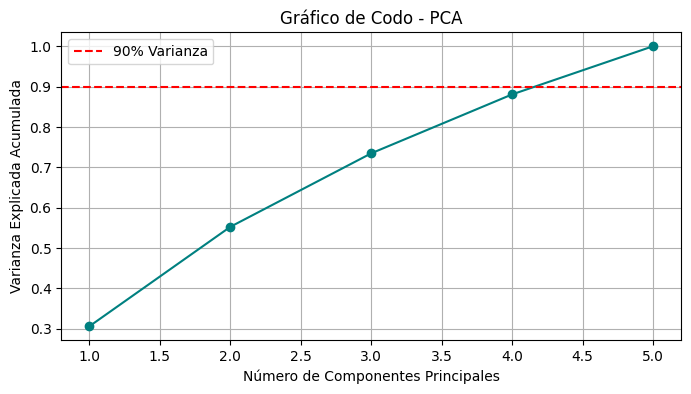

In [14]:
from sklearn.decomposition import PCA

# Seleccionamos variables predictoras estandarizadas
X = df_standard.drop(columns=["precio"])


pca = PCA()
pca.fit(X)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)

# Gráf. Codo
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker="o", color="teal")
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Varianza')
plt.xlabel("Número de Componentes Principales")
plt.ylabel("Varianza Explicada Acumulada")
plt.title("Gráfico de Codo - PCA")
plt.legend()
plt.grid(True)
plt.show()

- La línea de varianza explicada acumulada crece de forma casi constante, sin mostrar un "codo" o quiebre abrupto en los primeros puntos.   
- Al usar 4 componentes principales, el modelo logra capturar aproximadamente el 88% de la información total, quedando muy cerca pero por debajo de la línea roja que marca el umbral del 90%.  
- Para alcanzar el 100% de la varianza y superar el umbral exigido, es necesario utilizar los 5 componentes completos.

En otras palabras, el hecho de que necesitemos casi todos los componentes para llegar al 90% significa que nuestras variables aportan información única y poco redundante. No podemos comprimir el comportamiento de los productos de Falabella a solo 1 o 2 dimensiones sin perder detalles cruciales sobre cómo el vendedor, los descuentos y la marca afectan el precio final.

In [ ]:
# Limpiamos columnas de texto redundantes o auxiliares antes de exportar
columnas_a_borrar = [
    "marca",
    "marca_limpia",
    "segmento_precio",
    "nivel_desc",
    "nivel_desc_corto"
]
df_final.drop(columns=columnas_a_borrar, inplace=True, errors="ignore")

# Exportamos el dataset enriquecido y totalmente numérico/codificado
df_final.to_csv('../data/dataset_feature_engineering.csv', index=False, encoding='utf-8-sig')
print("Dimensiones del dataset final:", df_final.shape)
print("Dataset final guardado exitosamente como 'dataset_feature_engineering.csv'")

Dimensiones del dataset final: (1830, 39)
Dataset final guardado exitosamente como 'dataset_feature_engineering.csv'


In [16]:
display(df_final.head(2))
print(df_final.shape)
print(df_final.columns)

,nombre,vendedor,precio,precio_original,descuento,calificacion,cantidad_resenas,calificacion_con_resenas,ahorro,tiene_resenas,...,marca_Samsung,marca_Seisa,marca_Shield,marca_Space,marca_Ugreen,marca_Xiaomi,nivel_desc_sin_desc,nivel_desc_bajo,nivel_desc_medio,nivel_desc_alto
0,IPhone 14 128GB Morado Reacondicionado A2649,Por Electronic Deals Pe,1469.0,1999.0,26.51,4.2500,4,4.2500,530.0,1,...,0,0,0,0,0,0,0,0,1,0
1,Batería externa Power Bank 20000mAh Integrated...,Por Xiaomi Tienda Oficial,79.0,89.0,11.24,4.7273,22,4.7273,10.0,1,...,0,0,0,0,0,1,0,1,0,0


(1830, 39)
Index(['nombre', 'vendedor', 'precio', 'precio_original', 'descuento',
       'calificacion', 'cantidad_resenas', 'calificacion_con_resenas',
       'ahorro', 'tiene_resenas', 'precio_log', 'resenas_log',
       'vendedor_count', 'marca_count', 'marca_freq', 'segmento_precio_num',
       'marca_Apple', 'marca_Belkin', 'marca_Case', 'marca_Generico',
       'marca_Hoco', 'marca_Honor', 'marca_Ldnio', 'marca_Memo',
       'marca_Motorola', 'marca_Nillkin', 'marca_Oem', 'marca_Otra_marca',
       'marca_Ringke', 'marca_Samsung', 'marca_Seisa', 'marca_Shield',
       'marca_Space', 'marca_Ugreen', 'marca_Xiaomi', 'nivel_desc_sin_desc',
       'nivel_desc_bajo', 'nivel_desc_medio', 'nivel_desc_alto'],
      dtype='object')


# Conclusión del notebook de feature engineering

- Identificación del Valor de Marca (Brand Premium): Al separar marca_Apple o marca_Xiaomi en columnas independientes, el modelo de correlación podrá medir exactamente cuántos soles extra paga el consumidor únicamente por el logotipo impreso en el producto, aislando ese efecto de las especificaciones técnicas del equipo.

- Influencia del Tamaño del Vendedor: La variable matemática vendedor_count revela si existe un monopolio de precios. Permite analizar si las tiendas oficiales con inventarios gigantescos (como Falabella) manejan precios más agresivos o más costosos en comparación con los pequeños vendedores del Marketplace que buscan competir.

- Estrategia Promocional por Bloques: Con las columnas nivel_desc_alto o nivel_sin_desc, podemos cruzar los datos para descubrir la política de descuentos. Esto resuelve la incógnita de si las rebajas fuertes (ej. Cyber Wow) se aplican masivamente para liquidar la gama media (segmento_precio_num = 1), mientras que los equipos de gama premium son inelásticos (no bajan de precio).

- El Peso de la Validación Social: Las variables resenas_log y tiene_resenas traducen la interacción humana a números. Esto ayuda a responder si un alto volumen de opiniones empuja el precio hacia arriba (por alta demanda) o si, por el contrario, los productos de mayor precio del catálogo exhiben menos reseñas debido a su exclusividad y bajo nivel de rotación.

# **Análisis y Visualización de Datos**

**Objetivo:** Identificar patrones, relaciones, segmentaciones y anomalías comerciales en el catálogo de productos móviles de Falabella Perú para generar insights accionables que expliquen el comportamiento de los precios y las estrategias promocionales.

**Propósito de la sección:**
Tomar el dataset enriquecido (`dataset_feature_engineering.csv`), que ya cuenta con las variables transformadas, codificadas y escaladas, y aplicar técnicas de análisis exploratorio para responder a las hipótesis del negocio:
1. **Análisis de Segmentaciones:** Evaluar cómo se distribuye el catálogo por gamas de precio y cuantificar el peso de las principales marcas (Brand Premium).
2. **Exploración de Relaciones:** Determinar la relación entre el segmento de precio y el nivel de descuento aplicado, identificando la elasticidad de la demanda.
3. **Detección de Anomalías y Patrones:** Analizar la validación social cruzando el precio con el volumen de reseñas, así como la concentración de la oferta (vendedores).
4. **Generación de Insights:** Interpretar analíticamente los gráficos para proponer recomendaciones de negocio sustentadas en los datos.

## **1. Análisis de Segmentaciones (Gama y Marca)**

Para entender el mercado, primero debemos ver cómo está compuesto. Segmentaremos el catálogo por su gama de precio usando la variable creada en el Feature Engineering y analizaremos si la marca genera un "Brand Premium", es decir, si los consumidores pagan más solo por la marca.

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

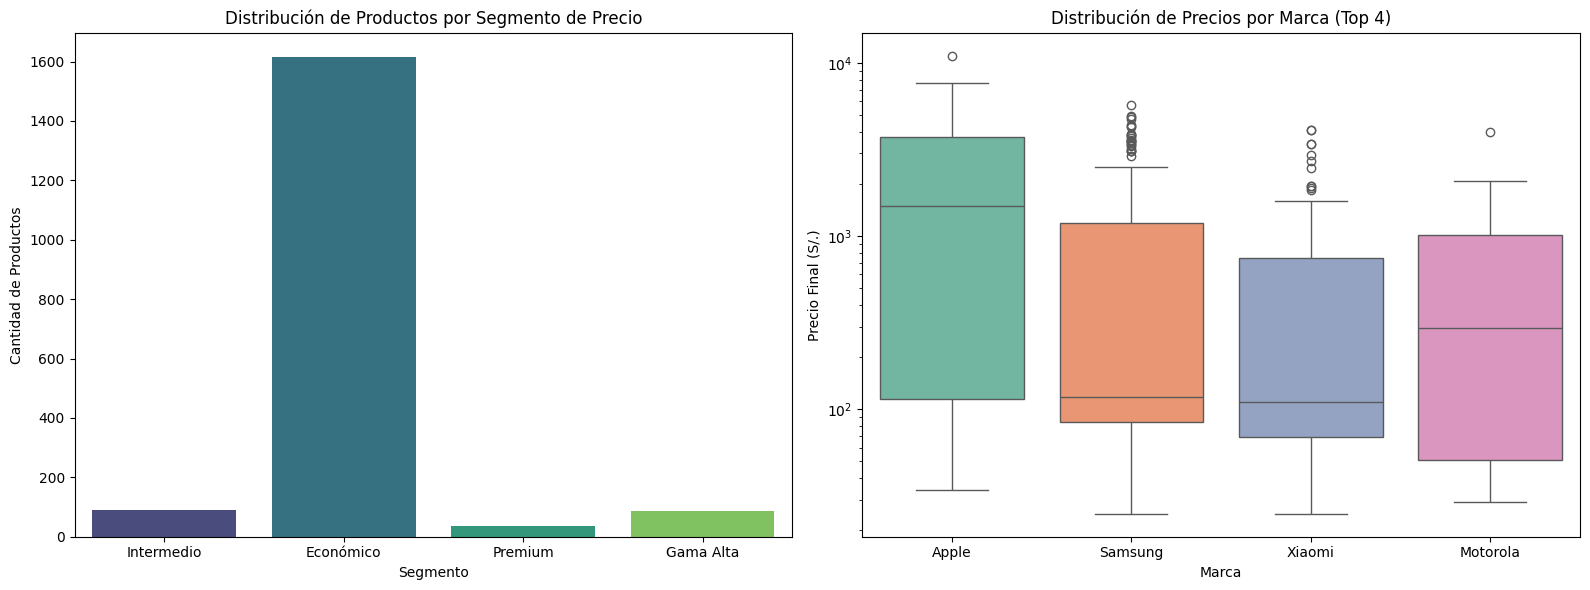

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Segmentación por Gama
mapeo = {0: 'Económico', 1: 'Intermedio', 2: 'Gama Alta', 3: 'Premium'}
df_final['Segmento_Nombre'] = df_final['segmento_precio_num'].map(mapeo)

sns.countplot(data=df_final, x='Segmento_Nombre', palette='viridis', ax=axes[0])
axes[0].set_title('Distribución de Productos por Segmento de Precio')
axes[0].set_ylabel('Cantidad de Productos')
axes[0].set_xlabel('Segmento')

# Patrón de Marca vs Precio 
marcas_top = ['marca_Apple', 'marca_Samsung', 'marca_Xiaomi', 'marca_Motorola']

df_marcas = df_final.melt(id_vars=['precio'], value_vars=marcas_top, var_name='Marca', value_name='Es_Marca')
df_marcas = df_marcas[df_marcas['Es_Marca'] == 1]
df_marcas['Marca'] = df_marcas['Marca'].str.replace('marca_', '')

sns.boxplot(data=df_marcas, x='Marca', y='precio', palette='Set2', ax=axes[1])
axes[1].set_title('Distribución de Precios por Marca (Top 4)')
axes[1].set_xlabel('Marca')
axes[1].set_ylabel('Precio Final (S/.)')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

Al observar la distribución del catálogo, salta a la vista que la gran mayoría de los productos pertenecen al segmento económico, lo que confirma que el ecosistema de accesorios móviles es el que mueve el volumen de inventario en la plataforma. Sin embargo, el análisis por marcas revela una historia distinta. Si bien Apple vende accesorios, su mediana de precios se dispara muy por encima del resto, superando los S/. 1,000, evidenciando un claro "Brand Premium". En contraste, marcas como Xiaomi y Motorola mantienen sus cajas comprimidas hacia la zona baja del gráfico, lo que demuestra que su estrategia comercial está anclada a la competitividad por precio y no al prestigio de marca.

## **2. Exploración de Relaciones y Detección de Anomalías**

En el comercio electrónico, es común que los descuentos se utilicen como herramientas para liquidar inventario de baja rotación. Asimismo, las reseñas de los usuarios suele tener comportamientos inesperados según el ticket de compra. A continuación, cruzamos estas variables para entender la elasticidad del precio y el comportamiento del consumidor.

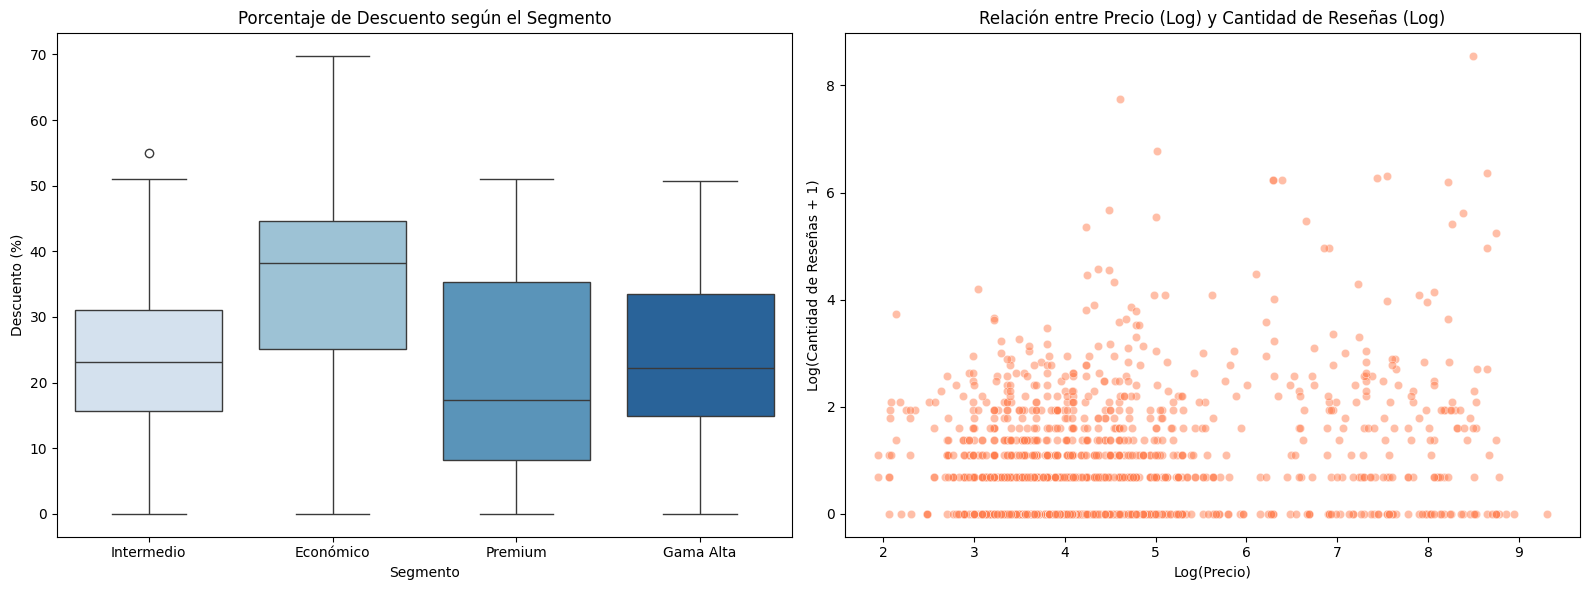

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Relación: Descuento por Segmento
sns.boxplot(data=df_final, x='Segmento_Nombre', y='descuento', palette='Blues', ax=axes[0])
axes[0].set_title('Porcentaje de Descuento según el Segmento')
axes[0].set_xlabel('Segmento')
axes[0].set_ylabel('Descuento (%)')

# Anomalía: Precio vs Reseñas
sns.scatterplot(data=df_final, x='precio_log', y='resenas_log', alpha=0.5, color='coral', ax=axes[1])
axes[1].set_title('Relación entre Precio (Log) y Cantidad de Reseñas (Log)')
axes[1].set_xlabel('Log(Precio)')
axes[1].set_ylabel('Log(Cantidad de Reseñas + 1)')

plt.tight_layout()
plt.show()

Al observar el comportamiento de los descuentos, identificamos una estrategia comercial muy marcada. Los productos de la **gama económica** concentran las rebajas más agresivas, con una mediana cercana al 40% y picos que rozan el 70%. Esto demuestra que la plataforma utiliza los descuentos altos como una herramienta de liquidación y rotación rápida para accesorios y equipos de bajo costo. En contraste, los productos de **gama alta y premium** presentan cajas más cortas y con medianas notablemente menores, alrededor del 20%, lo que evidencia una protección del valor percibido. Los equipos más costosos son prácticamente inelásticos a las rebajas masivas para no devaluar la marca.

Por otro lado, el gráfico de dispersión revela una anomalía de comportamiento del consumidor muy clara. Existe una gran densidad de puntos en la zona izquierda inferior, lo que significa que los productos económicos acumulan la mayor cantidad de reseñas. A medida que nos movemos hacia la derecha, donde están los productos más caros, los puntos se dispersan y se vuelven escasos. Esto demuestra que los compradores de productos de alto ticket en Falabella interactúan mucho menos en la plataforma; su decisión de compra probablemente está influenciada por factores externos, lealtad a la marca o especificaciones técnicas, y no tanto por las opiniones de otros usuarios.

## **3. Análisis de la Oferta y Concentración de Vendedores**

El precio no solo está determinado por las características del producto, sino también por quién lo vende. Analizaremos la concentración de la oferta para identificar si existe un dominio del retail tradicional o si el ecosistema del Marketplace tiene una presencia significativa.

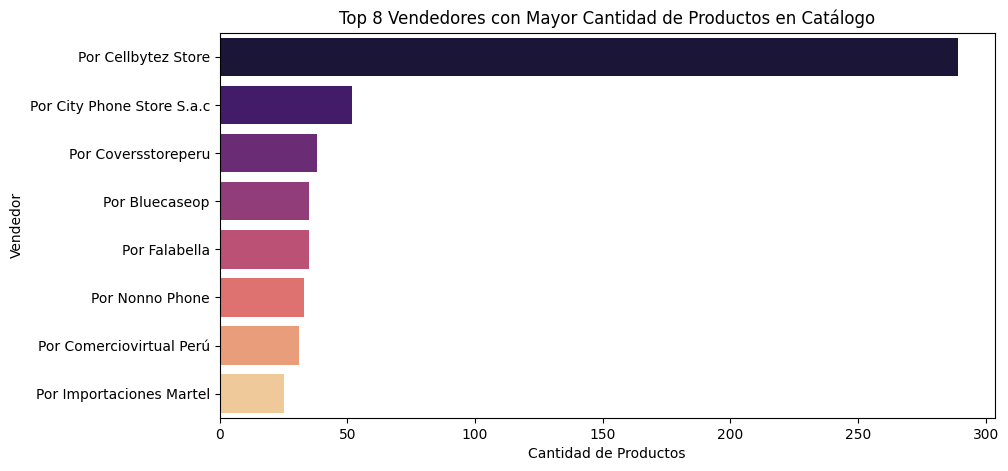

In [20]:
plt.figure(figsize=(10, 5))
top_vendedores = df_final['vendedor'].value_counts().head(8)

sns.barplot(x=top_vendedores.values, y=top_vendedores.index, palette='magma')
plt.title('Top 8 Vendedores con Mayor Cantidad de Productos en Catálogo')
plt.xlabel('Cantidad de Productos')
plt.ylabel('Vendedor')
plt.show()

El análisis de la oferta revela un gran hallazgo sobre la estructura del catálogo, el mercado está altamente concentrado. Un solo vendedor del Marketplace, *Cellbytez Store*, controla casi 300 productos, posicionándose muy por encima del propio *retail* tradicional, siendo este Falabella con menos de 50, y del resto de competidores. 

Esta anomalía indica que, aunque Falabella es la portada principal, el inventario tecnológico está siendo dominado por un *seller* tercero. Esta concentración tiene implicaciones directas en los precios, al tener un volumen tan masivo de productos, este vendedor tiene un gran poder de mercado. Además, el resto de la oferta está atomizada en tiendas especializadas, como *City Phone Store* o *Bluecaseop*, lo que sugiere que el consumidor que compra en Falabella está, en realidad, comprándole mayoritariamente a un ecosistema de revendedores del Marketplace.

## **4. Análisis de la Satisfacción del Cliente por Segmento**

Es fundamental evaluar la calidad percibida. Dado que anteriormente observamos que los productos de alta gama tienen muy pocas reseñas, resulta interesante comprobar si la calificación de esos pocos usuarios difiere de la satisfacción que reportan los compradores de productos económicos. Para ello, utilizaremos la variable `calificacion_con_resenas`, que aísla únicamente las valoraciones reales (ignorando los valores nulos o en cero de productos sin opiniones).

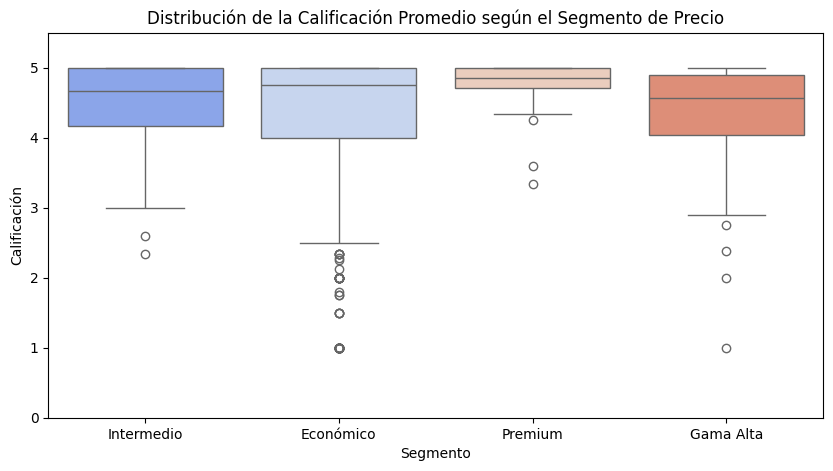

In [23]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df_final, x='Segmento_Nombre', y='calificacion_con_resenas', palette='coolwarm')

plt.title('Distribución de la Calificación Promedio según el Segmento de Precio')
plt.xlabel('Segmento')
plt.ylabel('Calificación')
plt.ylim(0, 5.5)
plt.show()

El gráfico de cajas revela que aunque el promedio general de calificaciones es alto, superando el 4.0 en todos los casos, la dispersión de los datos cuenta una historia distinta. El segmento **Económico** presenta una caja muy amplia y una gran cantidad de valores atípicos que descienden hasta 1.0. Esto refleja que, si bien los accesorios baratos se venden por volumen, su calidad es sumamente inconsistente, generando experiencias de compra muy negativas para una parte de los usuarios.

En marcado contraste, el segmento **Premium** muestra una caja extremadamente compacta, con su mediana y su límite inferior pegados al 5.0. Esto significa que, aunque los productos de alto costo reciben menos reseñas, como vimos en análisis anteriores, la satisfacción de quienes los compran es casi unánime. El comprador de alta gama es recompensado con una experiencia consistente y de alta calidad. 

Finalmente, la **Gama Alta** mantiene una buena calificación general, pero con una dispersión mayor que la Premium, lo que sugiere que en ese rango de precios todavía existe competencia y algunos productos no logran cumplir las expectativas del usuario.

## **5. El Verdadero Valor del Descuento**

Como último punto de exploración, es crucial analizar el impacto monetario de las rebajas. Un porcentaje de descuento puede ser engañoso si no se contextualiza con el precio base. Para entender el verdadero beneficio para el consumidor, analizamos el "ahorro absoluto", que sería la diferencia en soles entre el precio original y el precio final.

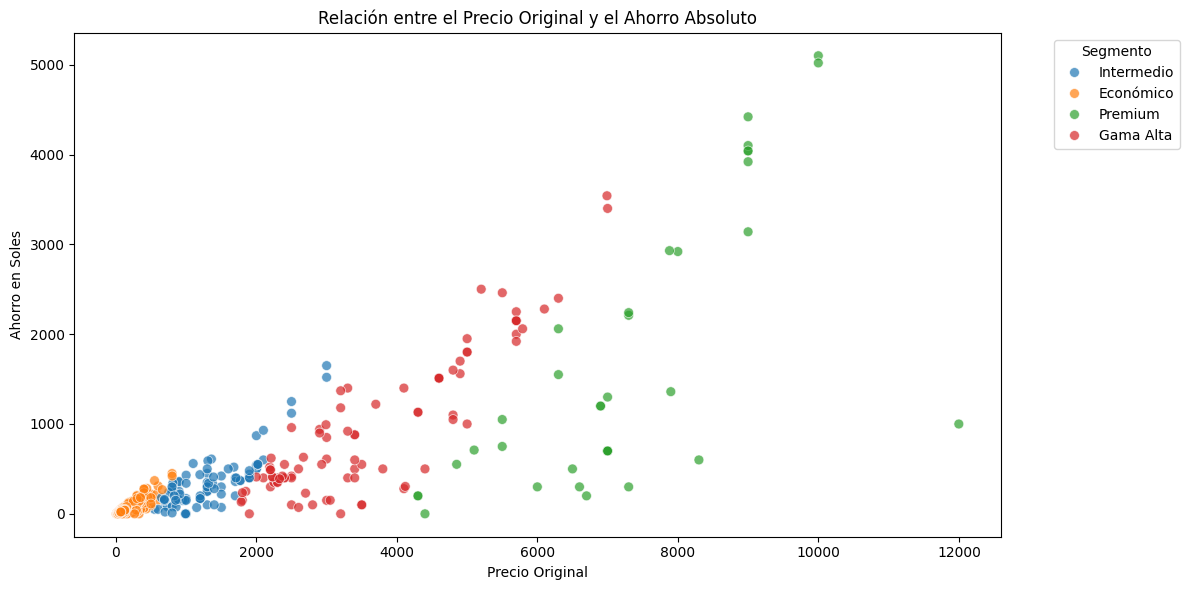

In [25]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df_final, 
    x='precio_original', 
    y='ahorro', 
    hue='Segmento_Nombre',
    alpha=0.7,
    s=50
)

plt.title('Relación entre el Precio Original y el Ahorro Absoluto')
plt.xlabel('Precio Original')
plt.ylabel('Ahorro en Soles')
plt.legend(title='Segmento', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

El análisis del ahorro monetario revela una separación natural del mercado. La gran masa naranja y azul (productos económicos e intermedios) se aglomera en la esquina inferior izquierda. Aunque en el análisis anterior vimos que estos productos tienen los porcentajes de descuento más altos, aquí comprobamos que su ahorro real en soles es marginal, situándose casi siempre por debajo de los S/ 500. Para el catálogo de bajo costo, las rebajas son más un gancho psicológico que un alivio financiero significativo.

Por otro lado, los puntos rojos (Gama Alta) y verdes (Premium) se despliegan hacia la derecha y hacia arriba. La dispersión es mucho mayor, encontramos equipos Premium con precios originales de S/ 6,000 que ofrecen ahorros reales de entre S/ 1,000 y S/ 2,500. Los casos más extremos generan ahorros que superan los S/ 5,000. Esto demuestra que la estrategia comercial está perfectamente segmentada, los descuentos porcentuales agresivos se usan para rotar accesorios, mientras que las rebajas de pocos puntos porcentuales en la gama alta son las que representan miles de soles de diferencia.

# **Conclusiones e Insights Estratégicos**

A partir del análisis exploratorio, se consolidan cuatro hallazgos clave que explican la dinámica de precios en el catálogo:

**El Brand Premium define el mercado.** La marca es el principal modulador del precio. Apple concentra su oferta en la cúspide (gama alta/premium), mientras que Xiaomi domina el volumen en el segmento económico.

**Estrategia de descuentos dual.** La plataforma usa rebajas agresivas superiores al 40% para liquidar accesorios de gama económica y gama media. En contraste, la gama premium es inelástica, sus descuentos porcentuales son mínimos para proteger el valor de marca, aunque en términos de **ahorro absoluto**, estos representan miles de soles, a diferencia de los accesorios baratos.

**La validación social y la calidad se comportan de forma inversa al precio.** Las reseñas masivas se concentran en productos económicos. Sin embargo, la calidad percibida es más consistente y alta en la gama Premium. El comprador de alto ticket no se guía por reseñas, sino por la seguridad de una experiencia externa.

**Concentración de la oferta.** El catálogo no está dominado por el *retail* tradicional, sino por vendedores terceros del Marketplace, liderados por *Cellbytez Store*, quienes controlan la mayor parte del inventario tecnológico.

**Recomendación de negocio:** Utilizar los accesorios económicos como productos "gancho" para generar tráfico y reseñas. Para la gama alta, evitar los descuentos porcentuales agresivos y enfocarse en valor agregado, como garantías, envíos, cuotas, para justificar el sobreprecio. Finalmente, los nuevos vendedores deben buscar nichos específicos para competir frente a los grandes monopolios del Marketplace.